## WEEK 10 - START

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
FIG_DIR = Path("../figures")

TRAIN_PATH = DATA_DIR / "train_model_reduced.csv"
TEST_PATH = DATA_DIR / "test_model_reduced.csv"
MODEL_PATH = MODEL_DIR / "week9_final_model.joblib"

RANDOM_STATE = 42

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)

print("Week 10: Data-Centric AI")
print("Working directory:", Path.cwd())
print("Training dataset available:", TRAIN_PATH.is_file())
print("Test dataset available:", TEST_PATH.is_file())
print("Week 9 model available:", MODEL_PATH.is_file())
print("Figures directory available:", FIG_DIR.is_dir())
print("Setup completed successfully!")

Week 10: Data-Centric AI
Working directory: C:\Users\david\Downloads\targeted-marketing-model-main\targeted-marketing-model-main\notebooks
Training dataset available: True
Test dataset available: True
Week 9 model available: True
Figures directory available: True
Setup completed successfully!


In [2]:
week9_model = joblib.load(MODEL_PATH)

C:\Users\david\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [3]:
final_model = week9_model["model"]
feature_names = week9_model["features"]
model_name = week9_model["name"]

print("Selected Model:", model_name)
print("Model Configuration:", final_model)
print("Number of Predictors:", len(feature_names))

Selected Model: W6 Logistic regression
Model Configuration: LogisticRegression(C=3, max_iter=5000, solver='liblinear')
Number of Predictors: 27


In [4]:
TARGET = "Response"

def load_week10_data(train_path, test_path, features):
    if not train_path.is_file() or not test_path.is_file():
        print("Processed datasets are not available yet.")
        print("Training path:", train_path)
        print("Test path:", test_path)
        return None, None

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    required_columns = features + [TARGET]

    for name, df in [("Training", train_df), ("Test", test_df)]:
        missing = [col for col in required_columns if col not in df.columns]

        if missing:
            raise ValueError(f"{name} dataset is missing columns: {missing}")

    print("Training dataset shape:", train_df.shape)
    print("Test dataset shape:", test_df.shape)
    print("Predictors verified:", len(features))

    return train_df, test_df

train_df, test_df = load_week10_data(
    TRAIN_PATH,
    TEST_PATH,
    feature_names
)

Training dataset shape: (1608, 28)
Test dataset shape: (412, 28)
Predictors verified: 27


### Baseline Model Evaluation

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    results = {
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities)
    }

    return pd.DataFrame([results])

if train_df is not None and test_df is not None:
    X_test = test_df[feature_names]
    y_test = test_df[TARGET]

    baseline_results = evaluate_model(final_model, X_test, y_test)
    display(baseline_results)
else:
    print("Baseline evaluation is ready.")
    print("Waiting for the processed datasets.")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.883495,0.692308,0.428571,0.529412,0.882772,0.665305


### Establish the Cross-Validation Baseline

In [6]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

X_train = train_df[feature_names]
y_train = train_df[TARGET]

baseline_cv = cross_validate(
    clone(final_model),
    X_train,
    y_train,
    cv=cv,
    scoring={
        "PR-AUC": "average_precision",
        "ROC-AUC": "roc_auc"
    },
    n_jobs=-1
)

baseline_cv_results = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC"],
    "Mean": [
        baseline_cv["test_PR-AUC"].mean(),
        baseline_cv["test_ROC-AUC"].mean()
    ],
    "Standard Deviation": [
        baseline_cv["test_PR-AUC"].std(),
        baseline_cv["test_ROC-AUC"].std()
    ]
})

display(baseline_cv_results.round(4))

,Metric,Mean,Standard Deviation
0,PR-AUC,0.7321,0.0653
1,ROC-AUC,0.9295,0.0176


### Experiment 1 — Outlier Treatment

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.lower_bounds_ = X.quantile(self.lower)
        self.upper_bounds_ = X.quantile(self.upper)
        return self

    def transform(self, X):
        return X.clip(
            lower=self.lower_bounds_,
            upper=self.upper_bounds_,
            axis=1
        )

outlier_pipeline = Pipeline([
    ("outlier_treatment", OutlierCapper()),
    ("model", clone(final_model))
])

outlier_cv = cross_validate(
    outlier_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "PR-AUC": "average_precision",
        "ROC-AUC": "roc_auc"
    },
    n_jobs=-1
)

outlier_results = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC"],
    "Baseline": [
        baseline_cv["test_PR-AUC"].mean(),
        baseline_cv["test_ROC-AUC"].mean()
    ],
    "Outlier Treatment": [
        outlier_cv["test_PR-AUC"].mean(),
        outlier_cv["test_ROC-AUC"].mean()
    ]
})

outlier_results["Difference"] = (
    outlier_results["Outlier Treatment"] - outlier_results["Baseline"]
)

display(outlier_results.round(4))

,Metric,Baseline,Outlier Treatment,Difference
0,PR-AUC,0.7321,0.7382,0.0061
1,ROC-AUC,0.9295,0.9310,0.0015


### Experiment 2 — Targeted Outlier Treatment

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

outlier_columns = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "Total_Spend",
    "Income_per_Person"
]

targeted_pipeline = Pipeline([
    (
        "outlier_treatment",
        ColumnTransformer(
            transformers=[
                ("cap", OutlierCapper(), outlier_columns)
            ],
            remainder="passthrough",
            verbose_feature_names_out=False
        )
    ),
    ("model", clone(final_model))
])

targeted_cv = cross_validate(
    targeted_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "PR-AUC": "average_precision",
        "ROC-AUC": "roc_auc"
    },
    n_jobs=-1
)

targeted_results = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC"],
    "Baseline": [
        baseline_cv["test_PR-AUC"].mean(),
        baseline_cv["test_ROC-AUC"].mean()
    ],
    "All-Feature Capping": [
        outlier_cv["test_PR-AUC"].mean(),
        outlier_cv["test_ROC-AUC"].mean()
    ],
    "Targeted Capping": [
        targeted_cv["test_PR-AUC"].mean(),
        targeted_cv["test_ROC-AUC"].mean()
    ]
})

display(targeted_results.round(4))

,Metric,Baseline,All-Feature Capping,Targeted Capping
0,PR-AUC,0.7321,0.7382,0.7293
1,ROC-AUC,0.9295,0.9310,0.9293


### Experiment 3 — Class Imbalance Treatment

In [9]:
from sklearn.model_selection import cross_validate
from sklearn.base import clone
from sklearn.utils import resample

oversampling_scores = {
    "PR-AUC": [],
    "ROC-AUC": []
}

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_data = X_fold_train.copy()
    fold_data["Response"] = y_fold_train.values

    majority = fold_data[fold_data["Response"] == 0]
    minority = fold_data[fold_data["Response"] == 1]

    minority_upsampled = resample(
        minority,
        replace=True,
        n_samples=len(majority),
        random_state=42
    )

    balanced_train = pd.concat(
        [majority, minority_upsampled],
        ignore_index=True
    )

    X_balanced = balanced_train[feature_names]
    y_balanced = balanced_train["Response"]

    model = clone(final_model)
    model.fit(X_balanced, y_balanced)

    probabilities = model.predict_proba(X_fold_val)[:, 1]

    oversampling_scores["PR-AUC"].append(
        average_precision_score(y_fold_val, probabilities)
    )

    oversampling_scores["ROC-AUC"].append(
        roc_auc_score(y_fold_val, probabilities)
    )

oversampling_results = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC"],
    "Baseline": [
        baseline_cv["test_PR-AUC"].mean(),
        baseline_cv["test_ROC-AUC"].mean()
    ],
    "Oversampling": [
        np.mean(oversampling_scores["PR-AUC"]),
        np.mean(oversampling_scores["ROC-AUC"])
    ]
})

oversampling_results["Difference"] = (
    oversampling_results["Oversampling"] -
    oversampling_results["Baseline"]
)

display(oversampling_results.round(4))

,Metric,Baseline,Oversampling,Difference
0,PR-AUC,0.7321,0.7249,-0.0072
1,ROC-AUC,0.9295,0.9283,-0.0013


### Compare Cross-Validation Performance

Mean improvement: 0.0061
Standard deviation of differences: 0.0098
Folds improved: 11 out of 15
Folds declined: 4 out of 15


,Fold,Baseline_PR_AUC,Outlier_PR_AUC,Improvement
0,1,0.8121,0.8199,0.0079
1,2,0.7379,0.7401,0.0022
2,3,0.7779,0.7806,0.0027
3,4,0.6768,0.7002,0.0234
4,5,0.6727,0.6877,0.0150
5,6,0.7134,0.7174,0.0040
6,7,0.7586,0.7770,0.0184
7,8,0.7795,0.7772,-0.0023
8,9,0.7252,0.7173,-0.0079
9,10,0.6837,0.6922,0.0085


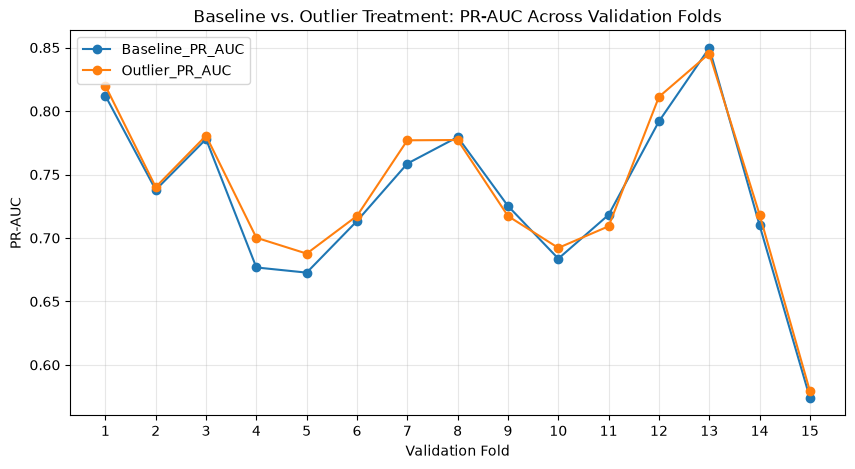

In [10]:
comparison = pd.DataFrame({
    "Fold": range(1, len(baseline_cv["test_PR-AUC"]) + 1),
    "Baseline_PR_AUC": baseline_cv["test_PR-AUC"],
    "Outlier_PR_AUC": outlier_cv["test_PR-AUC"]
})

comparison["Improvement"] = (
    comparison["Outlier_PR_AUC"] - comparison["Baseline_PR_AUC"]
)

print("Mean improvement:", round(comparison["Improvement"].mean(), 4))
print("Standard deviation of differences:", round(comparison["Improvement"].std(), 4))
print("Folds improved:", (comparison["Improvement"] > 0).sum(), "out of", len(comparison))
print("Folds declined:", (comparison["Improvement"] < 0).sum(), "out of", len(comparison))

display(comparison.round(4))

comparison[["Baseline_PR_AUC", "Outlier_PR_AUC"]].plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Baseline vs. Outlier Treatment: PR-AUC Across Validation Folds")
plt.xlabel("Validation Fold")
plt.ylabel("PR-AUC")
plt.xticks(range(len(comparison)), comparison["Fold"])
plt.grid(alpha=0.3)
plt.show()

### Final Evaluation on the Held-Out Test Set

In [11]:
baseline_refit = clone(final_model)
baseline_refit.fit(X_train, y_train)

final_outlier_model = Pipeline([
    ("outlier_treatment", OutlierCapper(lower=0.01, upper=0.99)),
    ("model", clone(final_model))
])

final_outlier_model.fit(X_train, y_train)

X_test = test_df[feature_names]
y_test = test_df[TARGET]

baseline_test = evaluate_model(baseline_refit, X_test, y_test)
outlier_test = evaluate_model(final_outlier_model, X_test, y_test)

final_comparison = pd.DataFrame({
    "Metric": baseline_test.columns,
    "Refitted Baseline": baseline_test.iloc[0].values,
    "Week 10 Outlier Treatment": outlier_test.iloc[0].values
})

final_comparison["Difference"] = (
    final_comparison["Week 10 Outlier Treatment"]
    - final_comparison["Refitted Baseline"]
)

display(final_comparison.round(4))

,Metric,Refitted Baseline,Week 10 Outlier Treatment,Difference
0,Accuracy,0.8835,0.8859,0.0024
1,Precision,0.6923,0.6905,-0.0018
2,Recall,0.4286,0.4603,0.0317
3,F1,0.5294,0.5524,0.0230
4,ROC-AUC,0.8828,0.8881,0.0053
5,PR-AUC,0.6653,0.6777,0.0124


### Final Results Summary and Visualization

,Experiment,PR-AUC,ROC-AUC
0,Baseline,0.7321,0.9295
1,All-Feature Outlier Capping,0.7382,0.9310
2,Targeted Outlier Capping,0.7293,0.9293
3,Random Oversampling,0.7249,0.9283


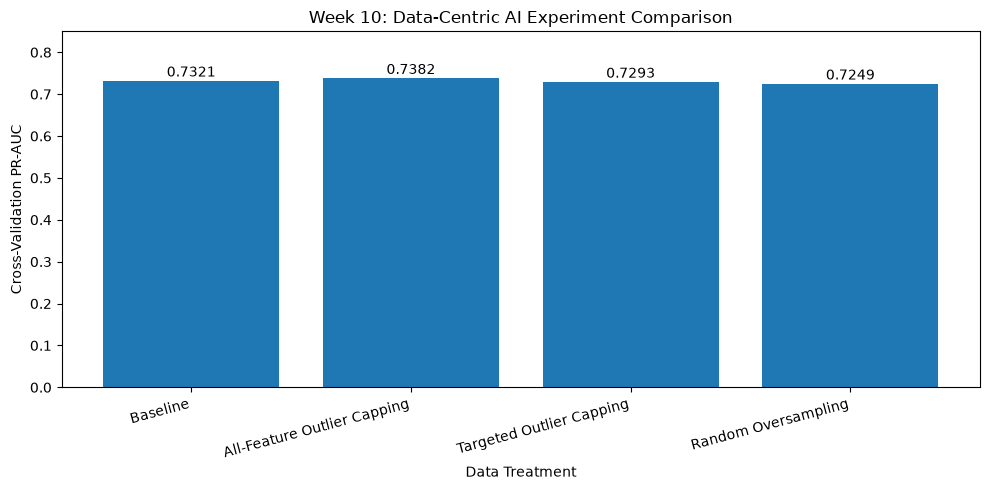

In [12]:
summary = pd.DataFrame({
    "Experiment": [
        "Baseline",
        "All-Feature Outlier Capping",
        "Targeted Outlier Capping",
        "Random Oversampling"
    ],
    "PR-AUC": [
        baseline_cv["test_PR-AUC"].mean(),
        outlier_cv["test_PR-AUC"].mean(),
        targeted_cv["test_PR-AUC"].mean(),
        np.mean(oversampling_scores["PR-AUC"])
    ],
    "ROC-AUC": [
        baseline_cv["test_ROC-AUC"].mean(),
        outlier_cv["test_ROC-AUC"].mean(),
        targeted_cv["test_ROC-AUC"].mean(),
        np.mean(oversampling_scores["ROC-AUC"])
    ]
})

display(summary.round(4))

plt.figure(figsize=(10, 5))

bars = plt.bar(summary["Experiment"], summary["PR-AUC"])

plt.title("Week 10: Data-Centric AI Experiment Comparison")
plt.xlabel("Data Treatment")
plt.ylabel("Cross-Validation PR-AUC")
plt.ylim(0, 0.85)
plt.xticks(rotation=15, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

## WEEK 10 - END